In [73]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
import numpy as np
from sklearn.model_selection import train_test_split
from qiskit_machine_learning.utils import algorithm_globals
from qiskit.circuit.library import ZZFeatureMap
from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel
import pandas as pd
from pymongo import MongoClient
from qiskit_machine_learning.algorithms import QSVC

In [74]:
def load_data_from_mongo(sample_limit=None,
                        num_labels=None,
                        uri="mongodb://localhost:27017/", 
                        db_name="Doodle_Classifier", 
                        collection_name="Filtered_Features",
                        ):
    try:
        client = MongoClient(uri)
        collection = client[db_name][collection_name]

        data = []
        
        # Get unique labels first
        all_unique_labels = collection.distinct("label")
        
        # Determine which labels to use
        if num_labels:
            if num_labels > len(all_unique_labels):
                print(f"Warning: Requested {num_labels} labels but only {len(all_unique_labels)} available")
                labels_to_use = all_unique_labels
            else:
                # Take first num_labels (you could randomize this if needed)
                labels_to_use = all_unique_labels[:num_labels]
                print(f"Using {num_labels} labels out of {len(all_unique_labels)} available")
        else:
            labels_to_use = all_unique_labels
            
        print(f"Selected labels: {labels_to_use}")
        
        if sample_limit:
            samples_per_label = sample_limit // len(labels_to_use)
            
            print(f"Found {len(all_unique_labels)} total unique labels")
            print(f"Using {len(labels_to_use)} labels")
            print(f"Sampling {samples_per_label} samples per label")
            
            # Sample equally from each selected label
            for label in labels_to_use:
                cursor = collection.find({"label": label}).limit(samples_per_label)
                for doc in cursor:
                    row = {
                        'label': doc["label"],
                        **doc["features"]
                    }
                    data.append(row)
        else:
            # Load all data for selected labels
            cursor = collection.find({"label": {"$in": labels_to_use}})
            for doc in cursor:
                row = {
                    'label': doc["label"],
                    **doc["features"]
                }
                data.append(row)
        
        client.close()
        
        if not data:
            raise ValueError("No data found in the collection")
            
        df = pd.DataFrame(data)
        X = df.drop(columns=['label']).values.astype(float)
        y = df['label'].values
        
        # Print label distribution
        unique_labels_loaded = np.unique(y, return_counts=True)
        print(f"Loaded {len(X)} samples with {X.shape[1]} features")
        print("Label distribution:")
        for label, count in zip(unique_labels_loaded[0], unique_labels_loaded[1]):
            print(f"  {label}: {count} samples")
            
        return X, y, df
        
    except Exception as e:
        print(f"Error loading data: {e}")
        return None, None, None

In [75]:
X,y,df = load_data_from_mongo(sample_limit=100,num_labels=2)

features_X = StandardScaler().fit_transform(X)
features = X

labels = y
encoded_labels = LabelEncoder().fit_transform(labels)

labels = encoded_labels

Using 2 labels out of 8 available
Selected labels: ['bicycle', 'car']
Found 8 total unique labels
Using 2 labels
Sampling 50 samples per label
Loaded 100 samples with 19 features
Label distribution:
  bicycle: 50 samples
  car: 50 samples


In [76]:
from sklearn.decomposition import PCA


algorithm_globals.random_seed = 123
np.random.seed(123)

components = 3
features = PCA(n_components=components).fit_transform(features_X)

train_features, test_features, train_labels, test_labels = train_test_split(
    features, labels, train_size=0.8, random_state=algorithm_globals.random_seed
)

In [77]:
def setup_quantum_kernel(n_features=5, reps=2, entanglement='linear'):

    feature_map = ZZFeatureMap(
        feature_dimension=n_features,
        reps=reps,
        entanglement=entanglement
    )
    
    # Create sampler
    sampler = Sampler()
    
    # Create fidelity calculator
    fidelity = ComputeUncompute(sampler=sampler)
    
    # Create quantum kernel
    quantum_kernel = FidelityQuantumKernel(
        fidelity=fidelity,
        feature_map=feature_map
    )
    
    print(f"✓ Quantum kernel initialized with {n_features} features")
    print(f"  - Feature Map: ZZFeatureMap")
    print(f"  - Reps: {reps}")
    print(f"  - Entanglement: {entanglement}")
    print(f"  - Backend: StatevectorSampler")
    
    return quantum_kernel


In [78]:
def train_qsvm_callable(X_train, y_train, quantum_kernel):

    print("\n[Training QSVM - Callable Kernel Method]")
    
    # Train SVM with kernel as callable function
    qsvm_callable = SVC(kernel=quantum_kernel.evaluate)
    qsvm_callable.fit(X_train, y_train)
    
    print("✓ QSVM (callable) training complete")
    return qsvm_callable

In [79]:
def train_qsvm_precomputed(X_train, y_train, quantum_kernel):
    print("\n[Training QSVM - Precomputed Kernel Method]")
    print("Computing quantum kernel matrix for training data...")
    
    # Compute quantum kernel matrix for training data
    train_kernel_matrix = quantum_kernel.evaluate(x_vec=X_train)
    
    # Train SVM with precomputed kernel
    qsvm_precomputed = SVC(kernel='precomputed')
    qsvm_precomputed.fit(train_kernel_matrix, y_train)
    
    print("✓ QSVM (precomputed) training complete")
    return qsvm_precomputed, train_kernel_matrix

In [80]:
def train_qsvc(X_train, y_train, quantum_kernel):
    
    print("\n[Training QSVC - Qiskit Implementation]")
    
    # Use Qiskit's QSVC
    qsvc = QSVC(quantum_kernel=quantum_kernel)
    qsvc.fit(X_train, y_train)
    
    print("✓ QSVC training complete")
    return qsvc

In [81]:
def evaluate_model(model, X_test, y_test, train_kernel_matrix=None, 
                   X_train=None, quantum_kernel=None, model_name="Model"):
    
    print(f"\n[Evaluating {model_name}]")
    
    # Get predictions and score
    if model_name == "QSVM (Precomputed)":
        # Compute test kernel matrix (test vs train)
        print("Computing quantum kernel matrix for test data...")
        test_kernel_matrix = quantum_kernel.evaluate(x_vec=X_test, y_vec=X_train)
        y_pred = model.predict(test_kernel_matrix)
        accuracy = model.score(test_kernel_matrix, y_test)
    else:
        # Direct prediction
        y_pred = model.predict(X_test)
        accuracy = model.score(X_test, y_test)
    
    # Calculate additional metrics
    f1 = f1_score(y_test, y_pred, average='weighted')
    cm = confusion_matrix(y_test, y_pred)
    
    # Print results
    print(f"\n{'='*50}")
    print(f"{model_name} Performance Metrics")
    print(f"{'='*50}")
    print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"F1-Score:  {f1:.4f}")
    print(f"{'='*50}\n")
    
    return {
        'predictions': y_pred,
        'accuracy': accuracy,
        'f1_score': f1,
        'confusion_matrix': cm
    }


In [82]:
def train_classical_svm(X_train, y_train, X_test, y_test):

    print("\n[Training Classical SVM - RBF Kernel]")
    
    # Train classical SVM with RBF kernel
    classical_svm = SVC(kernel='rbf', random_state=42)
    classical_svm.fit(X_train, y_train)
    
    print("✓ Classical SVM training complete")
    
    # Evaluate
    y_pred = classical_svm.predict(X_test)
    accuracy = classical_svm.score(X_test, y_test)
    f1 = f1_score(y_test, y_pred, average='weighted')
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"\n{'='*50}")
    print(f"Classical SVM Performance Metrics")
    print(f"{'='*50}")
    print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"F1-Score:  {f1:.4f}")
    print(f"{'='*50}\n")
    
    return {
        'predictions': y_pred,
        'accuracy': accuracy,
        'f1_score': f1,
        'confusion_matrix': cm
    }

In [83]:
def visualize_kernel_matrices(train_kernel_matrix, test_kernel_matrix):

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    
    # Training kernel matrix
    im1 = axs[0].imshow(
        np.asmatrix(train_kernel_matrix),
        interpolation="nearest",
        origin="upper",
        cmap="Blues"
    )
    axs[0].set_title("Quantum Training Kernel Matrix", fontsize=14, fontweight='bold')
    axs[0].set_xlabel("Sample Index")
    axs[0].set_ylabel("Sample Index")
    plt.colorbar(im1, ax=axs[0])
    
    # Testing kernel matrix
    im2 = axs[1].imshow(
        np.asmatrix(test_kernel_matrix),
        interpolation="nearest",
        origin="upper",
        cmap="Reds"
    )
    axs[1].set_title("Quantum Testing Kernel Matrix", fontsize=14, fontweight='bold')
    axs[1].set_xlabel("Training Sample Index")
    axs[1].set_ylabel("Test Sample Index")
    plt.colorbar(im2, ax=axs[1])
    
    plt.tight_layout()
    plt.show()


In [84]:
def visualize_predictions(X_test, y_test, results_dict):
    n_models = len(results_dict)
    fig, axes = plt.subplots(2, n_models, figsize=(6*n_models, 10))
    
    if n_models == 1:
        axes = axes.reshape(-1, 1)
    
    for idx, (model_name, results) in enumerate(results_dict.items()):
        # Plot predictions on PCA space
        scatter = axes[0, idx].scatter(
            X_test[:, 0], X_test[:, 1],
            c=results['predictions'], cmap='viridis',
            alpha=0.6, edgecolors='k', s=100
        )
        axes[0, idx].set_xlabel('PC1', fontsize=12)
        axes[0, idx].set_ylabel('PC2', fontsize=12)
        axes[0, idx].set_title(
            f'{model_name} Predictions\n(Acc: {results["accuracy"]:.3f})',
            fontsize=13, fontweight='bold'
        )
        axes[0, idx].grid(alpha=0.3)
        plt.colorbar(scatter, ax=axes[0, idx], label='Predicted Class')
        
        # Plot confusion matrix
        disp = ConfusionMatrixDisplay(confusion_matrix=results['confusion_matrix'])
        disp.plot(ax=axes[1, idx], cmap='Blues', values_format='d')
        axes[1, idx].set_title(
            f'{model_name} Confusion Matrix',
            fontsize=13, fontweight='bold'
        )
    
    plt.tight_layout()
    plt.show()

In [85]:
def print_comparison_table(results_dict):
    """
    Print comparison table of all models
    
    Args:
        results_dict: Dictionary containing results from different models
    """
    print("\n" + "="*70)
    print("MODEL COMPARISON SUMMARY")
    print("="*70)
    print(f"{'Model':<35} | {'Accuracy':>10} | {'F1-Score':>10}")
    print("-"*70)
    
    for model_name, results in results_dict.items():
        print(f"{model_name:<35} | {results['accuracy']:>10.4f} | {results['f1_score']:>10.4f}")
    
    print("="*70 + "\n")


In [86]:
X_train, X_test = train_features, test_features
y_train, y_test = train_labels, test_labels

QUANTUM SUPPORT VECTOR MACHINE (QSVM) CLASSIFICATION
Using Qiskit Machine Learning with FidelityQuantumKernel
Training samples: 80
Test samples:     20
Features (PCA):   3
✓ Quantum kernel initialized with 3 features
  - Feature Map: ZZFeatureMap
  - Reps: 2
  - Entanglement: linear
  - Backend: StatevectorSampler

[Training QSVM - Callable Kernel Method]
✓ QSVM (callable) training complete

[Evaluating QSVM (Callable)]

QSVM (Callable) Performance Metrics
Accuracy:  0.5000 (50.00%)
F1-Score:  0.5327


[Training QSVM - Precomputed Kernel Method]
Computing quantum kernel matrix for training data...
✓ QSVM (precomputed) training complete
Computing test kernel matrix...

[Evaluating QSVM (Precomputed)]
Computing quantum kernel matrix for test data...

QSVM (Precomputed) Performance Metrics
Accuracy:  0.4500 (45.00%)
F1-Score:  0.4459


[Visualizing Kernel Matrices]


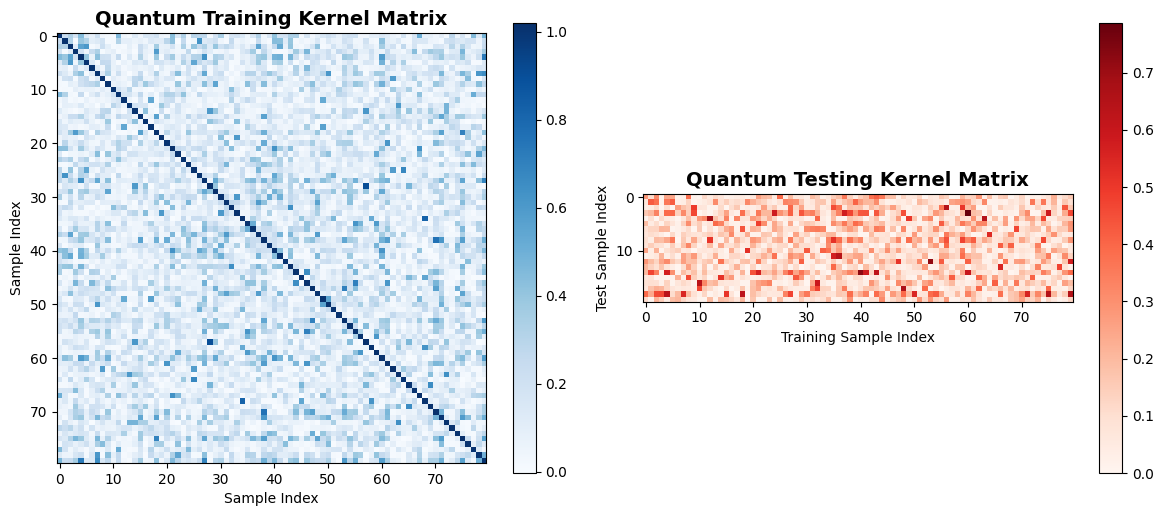


[Training QSVC - Qiskit Implementation]
✓ QSVC training complete

[Evaluating QSVC (Qiskit)]

QSVC (Qiskit) Performance Metrics
Accuracy:  0.6000 (60.00%)
F1-Score:  0.5466


[Training Classical SVM - RBF Kernel]
✓ Classical SVM training complete

Classical SVM Performance Metrics
Accuracy:  0.7500 (75.00%)
F1-Score:  0.7404


MODEL COMPARISON SUMMARY
Model                               |   Accuracy |   F1-Score
----------------------------------------------------------------------
QSVM (Callable)                     |     0.5000 |     0.5327
QSVM (Precomputed)                  |     0.4500 |     0.4459
QSVC (Qiskit)                       |     0.6000 |     0.5466
Classical SVM (RBF)                 |     0.7500 |     0.7404

[Generating Visualizations]


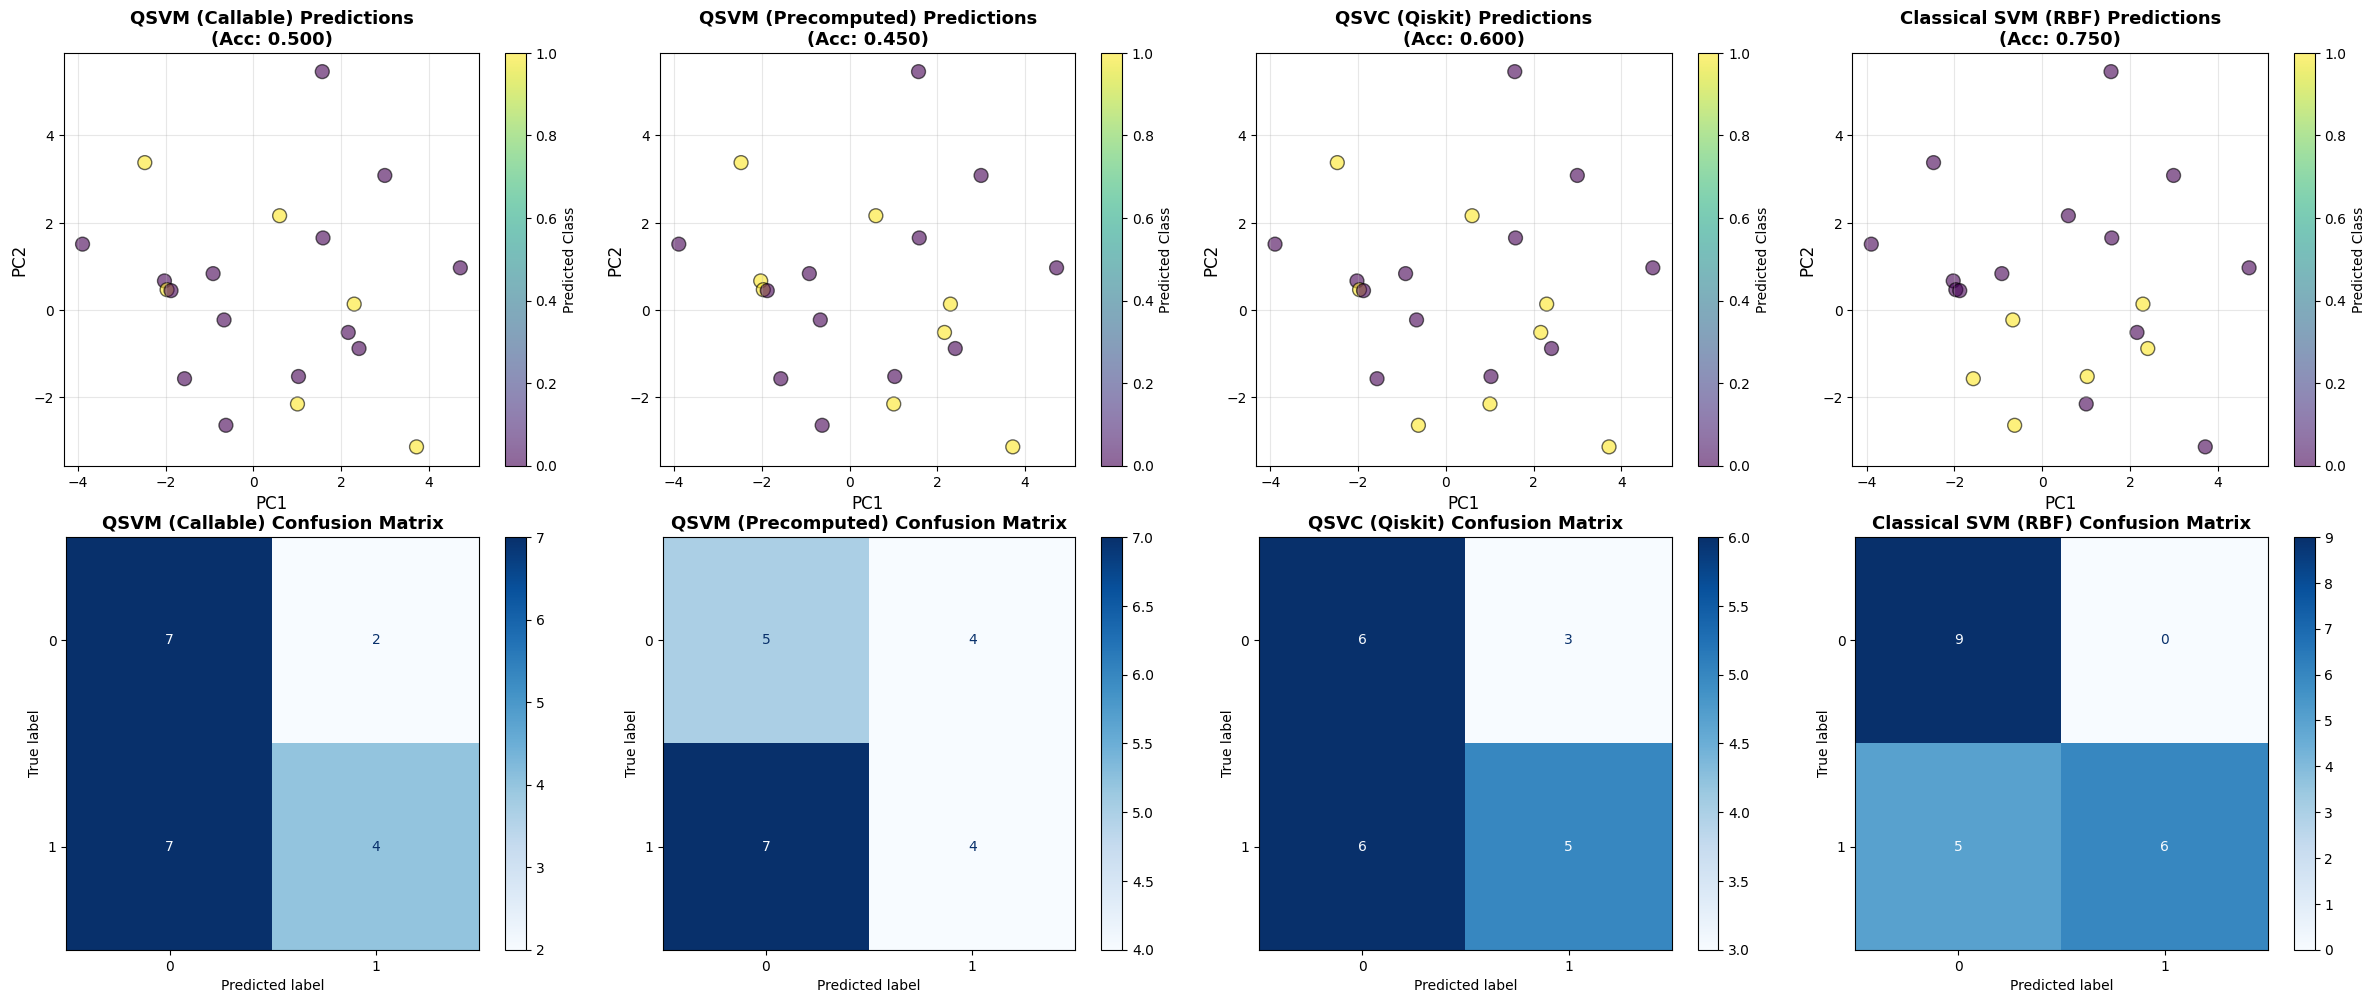

✓ All done!
qsvm_callable
qsvm_precomputed
qsvc
quantum_kernel
results


In [87]:
print("="*70)
print("QUANTUM SUPPORT VECTOR MACHINE (QSVM) CLASSIFICATION")
print("Using Qiskit Machine Learning with FidelityQuantumKernel")
print("="*70)
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print(f"Features (PCA):   {X_train.shape[1]}")
print("="*70)

# Setup quantum kernel
quantum_kernel = setup_quantum_kernel(
    n_features=X_train.shape[1],
    reps=2,
    entanglement='linear'
)

# Dictionary to store all results
all_results = {}

# Method 1: QSVM with callable kernel
qsvm_callable = train_qsvm_callable(X_train, y_train, quantum_kernel)
results_callable = evaluate_model(
    qsvm_callable, X_test, y_test,
    model_name="QSVM (Callable)"
)
all_results["QSVM (Callable)"] = results_callable

# Method 2: QSVM with precomputed kernel
qsvm_precomputed, train_kernel_matrix = train_qsvm_precomputed(
    X_train, y_train, quantum_kernel
)

# Compute test kernel matrix for visualization
print("Computing test kernel matrix...")
test_kernel_matrix = quantum_kernel.evaluate(x_vec=X_test, y_vec=X_train)

results_precomputed = evaluate_model(
    qsvm_precomputed, X_test, y_test,
    train_kernel_matrix=train_kernel_matrix,
    X_train=X_train,
    quantum_kernel=quantum_kernel,
    model_name="QSVM (Precomputed)"
)
all_results["QSVM (Precomputed)"] = results_precomputed

print("\n[Visualizing Kernel Matrices]")
visualize_kernel_matrices(train_kernel_matrix, test_kernel_matrix)

# Method 3: Qiskit QSVC
qsvc = train_qsvc(X_train, y_train, quantum_kernel)
results_qsvc = evaluate_model(
    qsvc, X_test, y_test,
    model_name="QSVC (Qiskit)"
)
all_results["QSVC (Qiskit)"] = results_qsvc

# Optional: Train and evaluate classical SVM
classical_results = train_classical_svm(X_train, y_train, X_test, y_test)
all_results["Classical SVM (RBF)"] = classical_results

# Print comparison table
print_comparison_table(all_results)

# Visualize all predictions
print("[Generating Visualizations]")
visualize_predictions(X_test, y_test, all_results)

print("✓ All done!")

final = {
    'qsvm_callable': qsvm_callable,
    'qsvm_precomputed': qsvm_precomputed,
    'qsvc': qsvc,
    'quantum_kernel': quantum_kernel,
    'results': all_results
}

print(*final,sep="\n")

In [88]:
X,y,df = load_data_from_mongo(sample_limit=200,num_labels=2)

features_X = StandardScaler().fit_transform(X)
features = X

labels = y
encoded_labels = LabelEncoder().fit_transform(labels)

labels = encoded_labels

Using 2 labels out of 8 available
Selected labels: ['bicycle', 'car']
Found 8 total unique labels
Using 2 labels
Sampling 100 samples per label
Loaded 200 samples with 19 features
Label distribution:
  bicycle: 100 samples
  car: 100 samples


In [ ]:
from sklearn.decomposition import PCA


algorithm_globals.random_seed = 123
np.random.seed(123)

components = 5
features = PCA(n_components=components).fit_transform(features_X)

train_features, test_features, train_labels, test_labels = train_test_split(
    features, labels, train_size=0.8, random_state=algorithm_globals.random_seed    
)

X_train, X_test = train_features, test_features
y_train, y_test = train_labels, test_labels


QUANTUM SUPPORT VECTOR MACHINE (QSVM) CLASSIFICATION
Using Qiskit Machine Learning with FidelityQuantumKernel
Training samples: 160
Test samples:     40
Features (PCA):   5
✓ Quantum kernel initialized with 5 features
  - Feature Map: ZZFeatureMap
  - Reps: 2
  - Entanglement: linear
  - Backend: StatevectorSampler

[Training QSVM - Callable Kernel Method]
✓ QSVM (callable) training complete

[Evaluating QSVM (Callable)]

QSVM (Callable) Performance Metrics
Accuracy:  0.4250 (42.50%)
F1-Score:  0.4013


[Training QSVM - Precomputed Kernel Method]
Computing quantum kernel matrix for training data...
✓ QSVM (precomputed) training complete
Computing test kernel matrix...

[Evaluating QSVM (Precomputed)]
Computing quantum kernel matrix for test data...

QSVM (Precomputed) Performance Metrics
Accuracy:  0.4750 (47.50%)
F1-Score:  0.4641


[Visualizing Kernel Matrices]


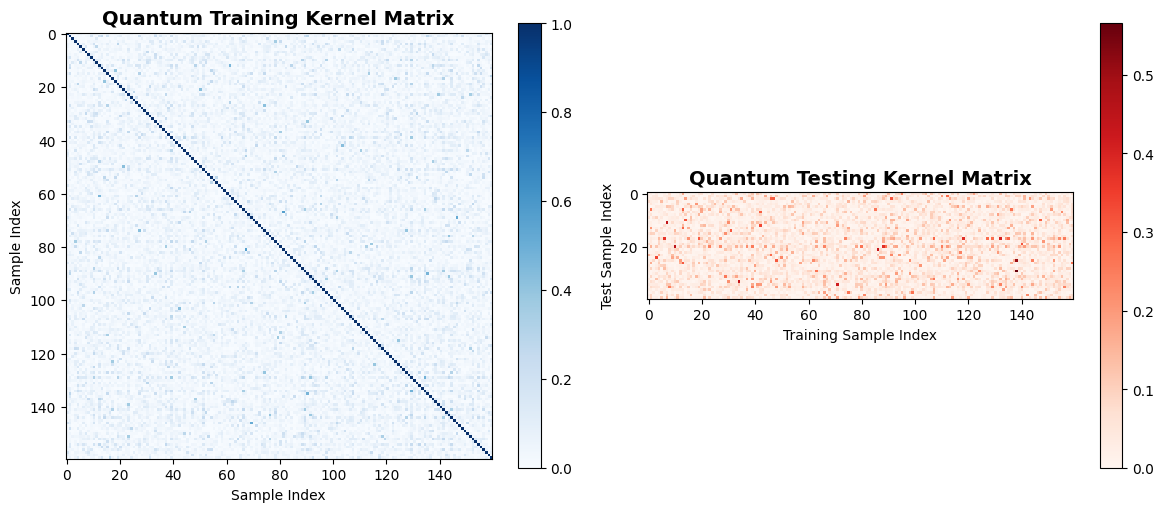


[Training QSVC - Qiskit Implementation]
✓ QSVC training complete

[Evaluating QSVC (Qiskit)]

QSVC (Qiskit) Performance Metrics
Accuracy:  0.4500 (45.00%)
F1-Score:  0.4533


[Training Classical SVM - RBF Kernel]
✓ Classical SVM training complete

Classical SVM Performance Metrics
Accuracy:  0.7250 (72.50%)
F1-Score:  0.7262


MODEL COMPARISON SUMMARY
Model                               |   Accuracy |   F1-Score
----------------------------------------------------------------------
QSVM (Callable)                     |     0.4250 |     0.4013
QSVM (Precomputed)                  |     0.4750 |     0.4641
QSVC (Qiskit)                       |     0.4500 |     0.4533
Classical SVM (RBF)                 |     0.7250 |     0.7262

[Generating Visualizations]


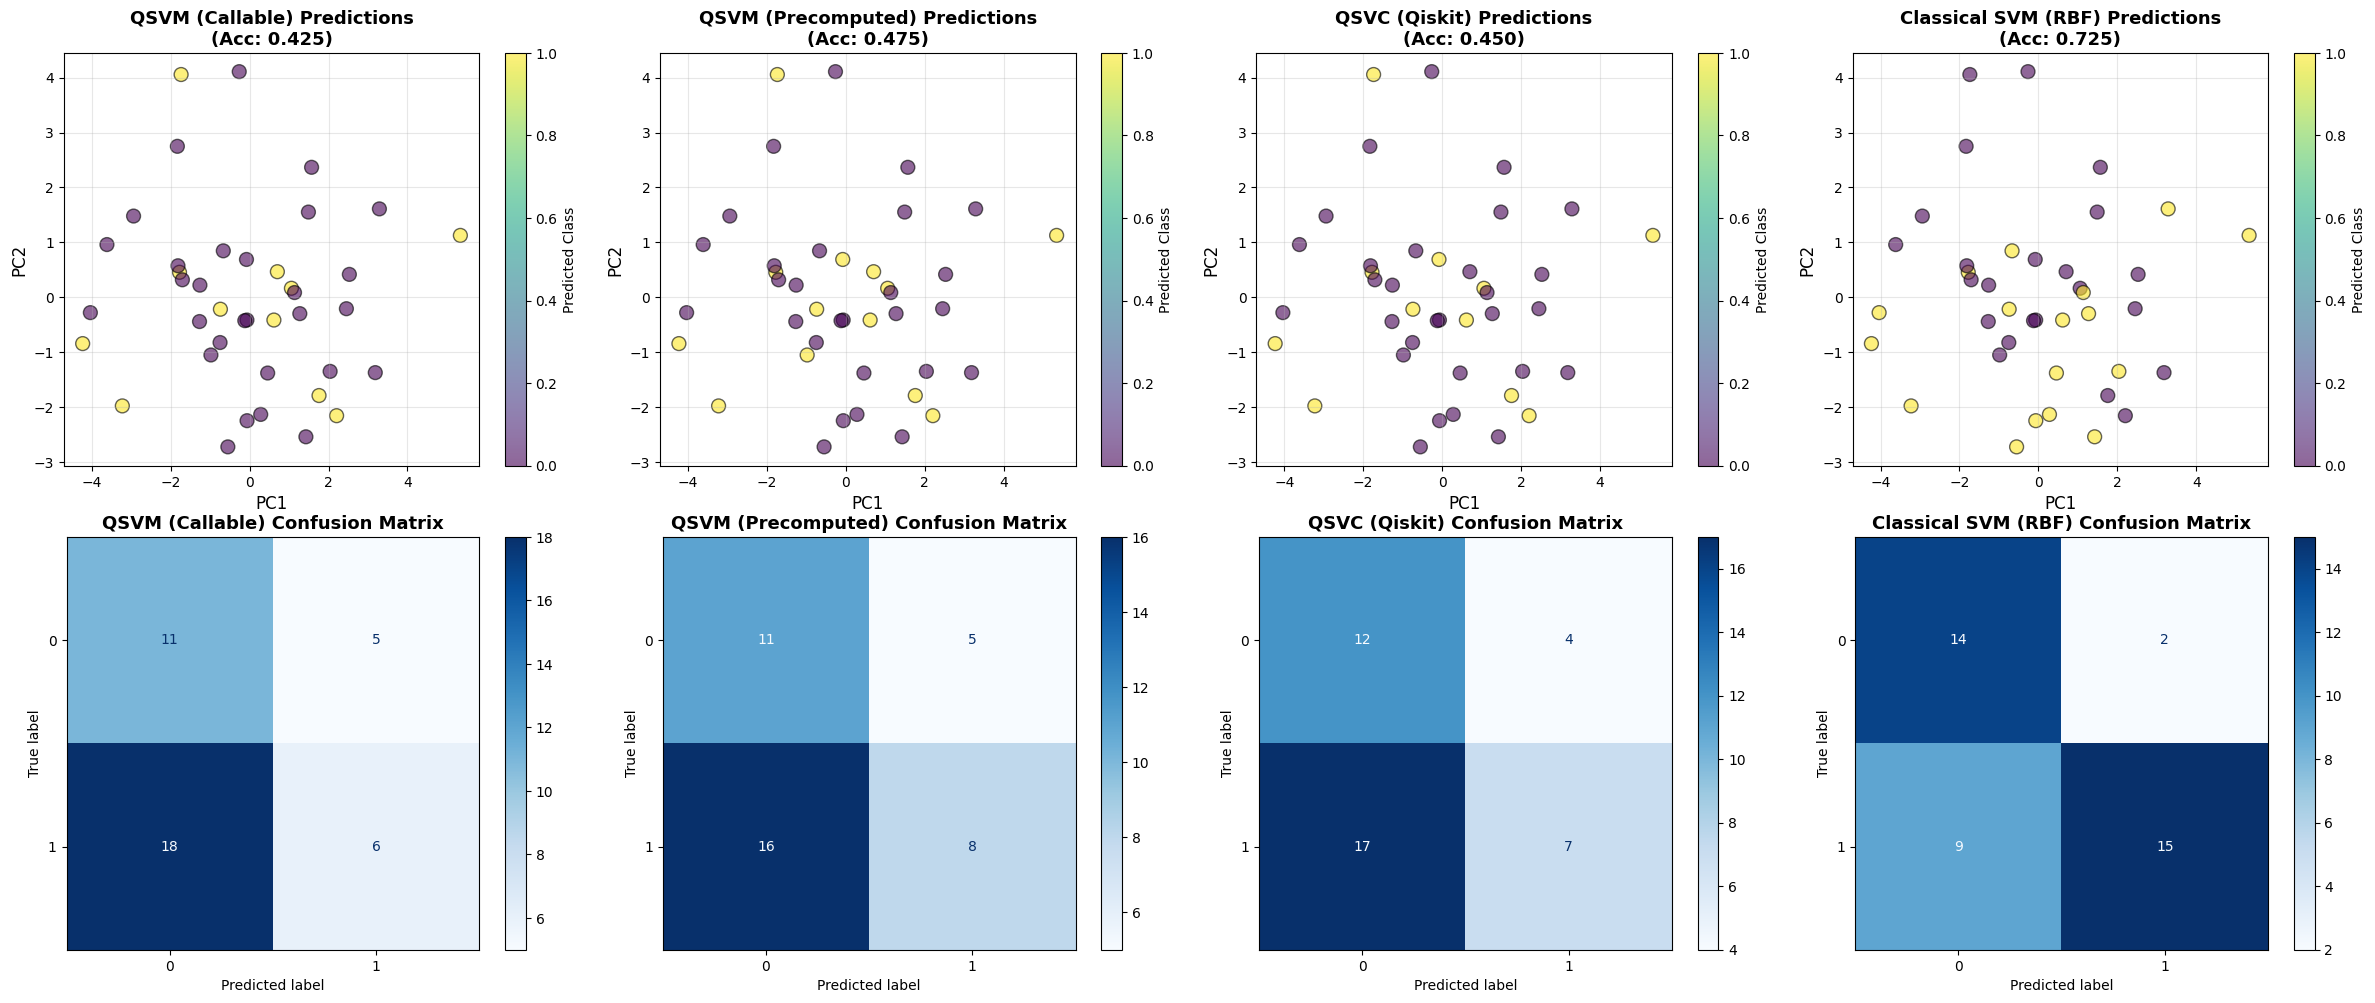

✓ All done!
qsvm_callable
qsvm_precomputed
qsvc
quantum_kernel
results


In [91]:
print("="*70)
print("QUANTUM SUPPORT VECTOR MACHINE (QSVM) CLASSIFICATION")
print("Using Qiskit Machine Learning with FidelityQuantumKernel")
print("="*70)
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print(f"Features (PCA):   {X_train.shape[1]}")
print("="*70)

# Setup quantum kernel
quantum_kernel = setup_quantum_kernel(
    n_features=X_train.shape[1],
    reps=2,
    entanglement='linear'
)

# Dictionary to store all results
all_results = {}

# Method 1: QSVM with callable kernel
qsvm_callable = train_qsvm_callable(X_train, y_train, quantum_kernel)
results_callable = evaluate_model(
    qsvm_callable, X_test, y_test,
    model_name="QSVM (Callable)"
)
all_results["QSVM (Callable)"] = results_callable

# Method 2: QSVM with precomputed kernel
qsvm_precomputed, train_kernel_matrix = train_qsvm_precomputed(
    X_train, y_train, quantum_kernel
)

# Compute test kernel matrix for visualization
print("Computing test kernel matrix...")
test_kernel_matrix = quantum_kernel.evaluate(x_vec=X_test, y_vec=X_train)

results_precomputed = evaluate_model(
    qsvm_precomputed, X_test, y_test,
    train_kernel_matrix=train_kernel_matrix,
    X_train=X_train,
    quantum_kernel=quantum_kernel,
    model_name="QSVM (Precomputed)"
)
all_results["QSVM (Precomputed)"] = results_precomputed

print("\n[Visualizing Kernel Matrices]")
visualize_kernel_matrices(train_kernel_matrix, test_kernel_matrix)

# Method 3: Qiskit QSVC
qsvc = train_qsvc(X_train, y_train, quantum_kernel)
results_qsvc = evaluate_model(
    qsvc, X_test, y_test,
    model_name="QSVC (Qiskit)"
)
all_results["QSVC (Qiskit)"] = results_qsvc

# Optional: Train and evaluate classical SVM
classical_results = train_classical_svm(X_train, y_train, X_test, y_test)
all_results["Classical SVM (RBF)"] = classical_results

# Print comparison table
print_comparison_table(all_results)

# Visualize all predictions
print("[Generating Visualizations]")
visualize_predictions(X_test, y_test, all_results)

print("✓ All done!")

final = {
    'qsvm_callable': qsvm_callable,
    'qsvm_precomputed': qsvm_precomputed,
    'qsvc': qsvc,
    'quantum_kernel': quantum_kernel,
    'results': all_results
}

print(*final,sep="\n")

In [93]:
X,y,df = load_data_from_mongo(sample_limit=200,num_labels=4)

features_X = StandardScaler().fit_transform(X)
features = X

labels = y
encoded_labels = LabelEncoder().fit_transform(labels)

labels = encoded_labels

from sklearn.decomposition import PCA


algorithm_globals.random_seed = 123
np.random.seed(123)

components = 5
features = PCA(n_components=components).fit_transform(features_X)

train_features, test_features, train_labels, test_labels = train_test_split(
    features, labels, train_size=0.8, random_state=algorithm_globals.random_seed    
)

X_train, X_test = train_features, test_features
y_train, y_test = train_labels, test_labels




Using 4 labels out of 8 available
Selected labels: ['bicycle', 'car', 'clock', 'fish']
Found 8 total unique labels
Using 4 labels
Sampling 50 samples per label
Loaded 200 samples with 19 features
Label distribution:
  bicycle: 50 samples
  car: 50 samples
  clock: 50 samples
  fish: 50 samples


In [94]:
print("="*70)
print("QUANTUM SUPPORT VECTOR MACHINE (QSVM) CLASSIFICATION")
print("Using Qiskit Machine Learning with FidelityQuantumKernel")
print("="*70)
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print(f"Features (PCA):   {X_train.shape[1]}")
print("="*70)

# Setup quantum kernel
quantum_kernel = setup_quantum_kernel(
    n_features=X_train.shape[1],
    reps=2,
    entanglement='linear'
)

# Dictionary to store all results
all_results = {}

# Method 1: QSVM with callable kernel
qsvm_callable = train_qsvm_callable(X_train, y_train, quantum_kernel)
results_callable = evaluate_model(
    qsvm_callable, X_test, y_test,
    model_name="QSVM (Callable)"
)
all_results["QSVM (Callable)"] = results_callable

# Method 2: QSVM with precomputed kernel
qsvm_precomputed, train_kernel_matrix = train_qsvm_precomputed(
    X_train, y_train, quantum_kernel
)

# Compute test kernel matrix for visualization
print("Computing test kernel matrix...")
test_kernel_matrix = quantum_kernel.evaluate(x_vec=X_test, y_vec=X_train)

results_precomputed = evaluate_model(
    qsvm_precomputed, X_test, y_test,
    train_kernel_matrix=train_kernel_matrix,
    X_train=X_train,
    quantum_kernel=quantum_kernel,
    model_name="QSVM (Precomputed)"
)
all_results["QSVM (Precomputed)"] = results_precomputed

print("\n[Visualizing Kernel Matrices]")
visualize_kernel_matrices(train_kernel_matrix, test_kernel_matrix)

# Method 3: Qiskit QSVC
qsvc = train_qsvc(X_train, y_train, quantum_kernel)
results_qsvc = evaluate_model(
    qsvc, X_test, y_test,
    model_name="QSVC (Qiskit)"
)
all_results["QSVC (Qiskit)"] = results_qsvc

# Optional: Train and evaluate classical SVM
classical_results = train_classical_svm(X_train, y_train, X_test, y_test)
all_results["Classical SVM (RBF)"] = classical_results

# Print comparison table
print_comparison_table(all_results)

# Visualize all predictions
print("[Generating Visualizations]")
visualize_predictions(X_test, y_test, all_results)

print("✓ All done!")

final = {
    'qsvm_callable': qsvm_callable,
    'qsvm_precomputed': qsvm_precomputed,
    'qsvc': qsvc,
    'quantum_kernel': quantum_kernel,
    'results': all_results
}

print(*final,sep="\n")

QUANTUM SUPPORT VECTOR MACHINE (QSVM) CLASSIFICATION
Using Qiskit Machine Learning with FidelityQuantumKernel
Training samples: 160
Test samples:     40
Features (PCA):   5
✓ Quantum kernel initialized with 5 features
  - Feature Map: ZZFeatureMap
  - Reps: 2
  - Entanglement: linear
  - Backend: StatevectorSampler

[Training QSVM - Callable Kernel Method]


KeyboardInterrupt: 